# Session 2 Seminar – 3.4 Scenario: Which customers will leave a positive review?

**Brief (slide 3.4):** Olist wants a model that predicts which customers will leave **positive reviews**, so it can target/incentivise them to write one. The task is to look through the data and identify **which features we could create that may be predictive** of a positive review.

**Approach in this notebook**
1. Load the 9 Olist tables and check them against the slide-3.5 *WARNINGS* (non-unique `customer_id`, multi-item orders, multi-seller orders).
2. Define the target: `positive_review = 1` if `review_score >= 4`.
3. Build the order-level analysis table (one row per order) using `merge()` and `groupby()` as in notebooks 2.02–2.04.
4. Create candidate features, grouped by theme: **delivery experience, order basket, payment, product, seller, customer, geography, timing**.
5. Test each feature's link to the target (positive-review rate by group, i.e. simple EDA as in 2.05).
6. Flag **data leakage**: features we must *not* use because they are only known after the review exists.
7. *(Beyond the brief)* A quick tree model to confirm which features actually carry signal.

> To run in Colab: upload the 9 CSVs with the cell below, or set `DATA_DIR` to wherever the files sit.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)

DATA_DIR = './'   # change if your CSVs are in another folder

# In Colab, uncomment the two lines below to upload the CSVs
# from google.colab import files
# upload = files.upload()

## 1. Load the data

In [2]:
reviews   = pd.read_csv(DATA_DIR + 'olist_order_reviews_dataset.csv')
orders    = pd.read_csv(DATA_DIR + 'olist_orders_dataset.csv')
customers = pd.read_csv(DATA_DIR + 'olist_customers_dataset.csv')
items     = pd.read_csv(DATA_DIR + 'olist_order_items_dataset.csv')
payments  = pd.read_csv(DATA_DIR + 'olist_order_payments_dataset.csv')
products  = pd.read_csv(DATA_DIR + 'olist_products_dataset.csv')
sellers   = pd.read_csv(DATA_DIR + 'olist_sellers_dataset.csv')
geo       = pd.read_csv(DATA_DIR + 'olist_geolocation_dataset.csv')
cat_trans = pd.read_csv(DATA_DIR + 'product_category_name_translation.csv')

for name, df in [('reviews', reviews), ('orders', orders), ('customers', customers), ('items', items),
                 ('payments', payments), ('products', products), ('sellers', sellers), ('geo', geo)]:
    print(f'{name:10s} {df.shape}')

reviews    (89999, 7)
orders     (99441, 8)
customers  (99441, 5)
items      (112650, 7)
payments   (103886, 5)
products   (32951, 9)
sellers    (3095, 4)
geo        (1000163, 5)


### Checking the slide-3.5 warnings
Before joining, confirm the grain of each table – otherwise a merge silently duplicates rows and inflates everything.

In [3]:
print('Orders per customer_id (max):        ', customers.groupby('customer_id').size().max())
print('Orders per customer_unique_id (max): ', customers.groupby('customer_unique_id').size().max())
print('Customers with >1 order:             ', (customers.groupby('customer_unique_id').size() > 1).sum())
print('Orders with >1 item:                 ', (items.groupby('order_id').size() > 1).sum())
print('Orders with >1 seller:               ', (items.groupby('order_id')['seller_id'].nunique() > 1).sum())
print('Orders with >1 review:               ', reviews['order_id'].duplicated().sum())
print('Geo rows per zip prefix (mean):      ', round(geo.groupby('geolocation_zip_code_prefix').size().mean(), 1))

Orders per customer_id (max):         1
Orders per customer_unique_id (max):  17


Customers with >1 order:              2997


Orders with >1 item:                  9803
Orders with >1 seller:                1278
Orders with >1 review:                447
Geo rows per zip prefix (mean):       52.6


Implications:
- **Reviews** – a few orders have more than one review. Keep the **latest** review per order so each order has one target value.
- **Items / payments** – several rows per order, so **aggregate to order level** before merging.
- **Geolocation** – many lat/lng rows per zip prefix, so take the **mean lat/lng per prefix** before merging, otherwise the join multiplies rows.
- **Customers** – use `customer_unique_id` to spot repeat buyers (`customer_id` is new for every order).

## 2. Target variable

In [4]:
# NB: the review dates in this file are day-first (dd/mm/yyyy), unlike the other tables
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'], dayfirst=True)
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'], dayfirst=True)

# keep the most recent review for each order
reviews = (reviews.sort_values('review_answer_timestamp')
                  .drop_duplicates('order_id', keep='last'))

reviews['positive_review'] = np.where(reviews['review_score'] >= 4, 1, 0)

print(reviews['review_score'].value_counts(normalize=True).sort_index())
print('\nPositive (4-5*) share:', round(reviews['positive_review'].mean(), 3))

review_score
1   0.118
2   0.032
3   0.083
4   0.192
5   0.575
Name: proportion, dtype: float64

Positive (4-5*) share: 0.767


About **77%** of reviews are positive, so the classes are imbalanced. A model that always predicts "positive" is already 77% accurate. That is why the evaluation later uses **ROC-AUC**, not accuracy.

*Design choice:* 4★ and 5★ count as positive. An alternative is "5★ only" (57%), which is a stricter target if Olist only wants to incentivise its happiest customers.

## 3. Build the order-level table

### 3a. Orders + delivery timing features

In [5]:
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

o = orders.copy()
day = pd.Timedelta(days=1)

# --- Delivery experience (theory: customers review the *experience*, not just the product)
o['delivery_days']        = (o['order_delivered_customer_date'] - o['order_purchase_timestamp']) / day
o['promised_days']        = (o['order_estimated_delivery_date'] - o['order_purchase_timestamp']) / day
o['days_vs_estimate']     = (o['order_delivered_customer_date'] - o['order_estimated_delivery_date']) / day  # +ve = late
o['is_late']              = np.where(o['days_vs_estimate'] > 0, 1, 0)
o['approval_hours']       = (o['order_approved_at'] - o['order_purchase_timestamp']) / pd.Timedelta(hours=1)
o['seller_dispatch_days'] = (o['order_delivered_carrier_date'] - o['order_approved_at']) / day
o['carrier_days']         = (o['order_delivered_customer_date'] - o['order_delivered_carrier_date']) / day
o['is_delivered']         = np.where(o['order_status'] == 'delivered', 1, 0)

# --- Timing of purchase
o['purchase_month']   = o['order_purchase_timestamp'].dt.month
o['purchase_dow']     = o['order_purchase_timestamp'].dt.dayofweek   # 0 = Monday
o['purchase_hour']    = o['order_purchase_timestamp'].dt.hour
o['is_weekend']       = np.where(o['purchase_dow'] >= 5, 1, 0)
o['black_friday_xmas'] = np.where(o['order_purchase_timestamp'].dt.month.isin([11, 12]), 1, 0)

o[['delivery_days', 'promised_days', 'days_vs_estimate', 'is_late', 'seller_dispatch_days', 'carrier_days']].describe()

,delivery_days,promised_days,days_vs_estimate,is_late,seller_dispatch_days,carrier_days
count,96476.000,99441.000,96476.000,99441.000,97644.000,96475.000
mean,12.559,23.768,-11.179,0.079,2.805,9.331
std,9.547,8.832,10.186,0.269,3.549,8.760
min,0.533,1.649,-146.016,0.000,-171.219,-16.096
25%,6.766,18.332,-16.244,0.000,0.876,4.100
50%,10.218,23.240,-11.949,0.000,1.818,7.100
75%,15.720,28.425,-6.390,0.000,3.580,12.029
max,209.629,155.135,188.975,1.000,125.763,205.191


### 3b. Basket features (items aggregated to order level)

In [6]:
items_p = (items.merge(products, on='product_id', how='left')
                .merge(cat_trans, on='product_category_name', how='left'))
items_p['volume_cm3'] = items_p['product_length_cm'] * items_p['product_height_cm'] * items_p['product_width_cm']

basket = items_p.groupby('order_id').agg(
    n_items            = ('order_item_id', 'count'),
    n_distinct_products= ('product_id', 'nunique'),
    n_sellers          = ('seller_id', 'nunique'),
    n_categories       = ('product_category_name', 'nunique'),
    order_price        = ('price', 'sum'),
    order_freight      = ('freight_value', 'sum'),
    max_item_price     = ('price', 'max'),
    total_weight_g     = ('product_weight_g', 'sum'),
    total_volume_cm3   = ('volume_cm3', 'sum'),
    avg_photos         = ('product_photos_qty', 'mean'),
    avg_desc_length    = ('product_description_lenght', 'mean'),
    avg_name_length    = ('product_name_lenght', 'mean'),
    shipping_limit     = ('shipping_limit_date', 'max'),
).reset_index()

basket['freight_ratio']     = basket['order_freight'] / basket['order_price']
basket['multi_seller']      = np.where(basket['n_sellers'] > 1, 1, 0)
basket['repeat_same_item']  = np.where(basket['n_items'] > basket['n_distinct_products'], 1, 0)

# main category = category of the most expensive item in the order
main_cat = (items_p.sort_values('price', ascending=False)
                   .drop_duplicates('order_id')[['order_id', 'product_category_name_english', 'seller_id']]
                   .rename(columns={'product_category_name_english': 'main_category', 'seller_id': 'main_seller_id'}))
basket = basket.merge(main_cat, on='order_id', how='left')
basket.head()

,order_id,n_items,n_distinct_products,n_sellers,n_categories,order_price,order_freight,max_item_price,total_weight_g,total_volume_cm3,avg_photos,avg_desc_length,avg_name_length,shipping_limit,freight_ratio,multi_seller,repeat_same_item,main_category,main_seller_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,1,58.900,13.290,58.900,650.000,3528.000,4.000,598.000,58.000,2017-09-19 09:45:35,0.226,0,0,cool_stuff,48436dade18ac8b2bce089ec2a041202
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,1,239.900,19.930,239.900,30000.000,60000.000,2.000,239.000,56.000,2017-05-03 11:05:13,0.083,0,0,pet_shop,dd7ddc04e1b6c2c614352b383efe2d36
2,000229ec398224ef6ca0657da4fc703e,1,1,1,1,199.000,17.870,199.000,3050.000,14157.000,2.000,695.000,59.000,2018-01-18 14:48:30,0.090,0,0,furniture_decor,5b51032eddd242adc84c38acab88f23d
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,1,12.990,12.790,12.990,200.000,2400.000,1.000,480.000,42.000,2018-08-15 10:10:18,0.985,0,0,perfumery,9d7a1d34a5052409006425275ba1c2b4
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,1,199.900,18.140,199.900,3750.000,42000.000,1.000,409.000,59.000,2017-02-13 13:57:51,0.091,0,0,garden_tools,df560393f3a51e74553ab94004ba5c87


### 3c. Payment features

In [7]:
pay = payments.groupby('order_id').agg(
    payment_value     = ('payment_value', 'sum'),
    n_payment_methods = ('payment_sequential', 'max'),
    max_installments  = ('payment_installments', 'max'),
).reset_index()

main_pay = (payments.sort_values('payment_value', ascending=False)
                    .drop_duplicates('order_id')[['order_id', 'payment_type']]
                    .rename(columns={'payment_type': 'main_payment_type'}))
voucher = (payments.assign(v=payments['payment_type'].eq('voucher'))
                   .groupby('order_id')['v'].max().astype(int).rename('used_voucher').reset_index())

pay = pay.merge(main_pay, on='order_id').merge(voucher, on='order_id')
pay['uses_installments'] = np.where(pay['max_installments'] > 1, 1, 0)
pay.head()

,order_id,payment_value,n_payment_methods,max_installments,main_payment_type,used_voucher,uses_installments
0,00010242fe8c5a6d1ba2dd792cb16214,72.190,1,2,credit_card,0,1
1,00018f77f2f0320c557190d7a144bdd3,259.830,1,3,credit_card,0,1
2,000229ec398224ef6ca0657da4fc703e,216.870,1,5,credit_card,0,1
3,00024acbcdf0a6daa1e931b038114c75,25.780,1,2,credit_card,0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.040,1,3,credit_card,0,1


### 3d. Geography: customer–seller distance

In [8]:
# one lat/lng per zip prefix (mean), so the join does not duplicate rows
geo_zip = (geo.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']]
              .mean().reset_index())

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

cust_geo = (customers.merge(geo_zip, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
                     .rename(columns={'geolocation_lat': 'cust_lat', 'geolocation_lng': 'cust_lng'})
                     .drop(columns='geolocation_zip_code_prefix'))
sell_geo = (sellers.merge(geo_zip, left_on='seller_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
                   .rename(columns={'geolocation_lat': 'sell_lat', 'geolocation_lng': 'sell_lng'})
                   .drop(columns='geolocation_zip_code_prefix'))
cust_geo.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cust_lat,cust_lng
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,-20.498,-47.397
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,-23.728,-46.543
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,-23.532,-46.656
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,-23.500,-46.185
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,-22.975,-47.143


### 3e. Join everything into one row per reviewed order

In [9]:
df = (reviews[['review_id', 'order_id', 'review_score', 'positive_review', 'review_creation_date',
               'review_answer_timestamp', 'review_comment_message']]
      .merge(o, on='order_id', how='left')
      .merge(cust_geo, on='customer_id', how='left')
      .merge(basket, on='order_id', how='left')
      .merge(pay, on='order_id', how='left')
      .merge(sell_geo, left_on='main_seller_id', right_on='seller_id', how='left'))

df['cust_seller_km'] = haversine_km(df['cust_lat'], df['cust_lng'], df['sell_lat'], df['sell_lng'])
df['same_state']     = np.where(df['customer_state'] == df['seller_state'], 1, 0)
df['has_items']      = np.where(df['n_items'].notna(), 1, 0)

# Was the product delivered before Olist sent the review survey?
df['delivered_before_survey'] = np.where(df['order_delivered_customer_date'] <= df['review_creation_date'], 1, 0)

print(df.shape, '| duplicated orders:', df['order_id'].duplicated().sum())

(89552, 67) | duplicated orders: 0


### 3f. History features (repeat customer, seller reputation)
These need care. A seller's average score is only valid if it uses **reviews from *before* this order**. If it includes this order's own review, the target leaks into the feature. The code sorts by purchase date and uses a shifted expanding mean, so each row only sees the past.

In [10]:
df = df.sort_values('order_purchase_timestamp').reset_index(drop=True)

# customer history (customer_unique_id, per the slide warning)
df['cust_prior_orders'] = df.groupby('customer_unique_id').cumcount()
df['is_repeat_customer'] = np.where(df['cust_prior_orders'] > 0, 1, 0)
df['cust_prior_pos_rate'] = (df.groupby('customer_unique_id')['positive_review']
                               .transform(lambda s: s.shift().expanding().mean()))

# seller reputation built only from that seller's earlier orders
g = df.groupby('main_seller_id')['positive_review']
df['seller_prior_orders']   = df.groupby('main_seller_id').cumcount()
df['seller_prior_pos_rate'] = g.transform(lambda s: s.shift().expanding().mean())
df['seller_prior_late_rate'] = (df.groupby('main_seller_id')['is_late']
                                  .transform(lambda s: s.shift().expanding().mean()))

df[['cust_prior_orders', 'is_repeat_customer', 'seller_prior_orders', 'seller_prior_pos_rate']].describe()

,cust_prior_orders,is_repeat_customer,seller_prior_orders,seller_prior_pos_rate
count,89552.000,89552.000,88853.000,85841.000
mean,0.037,0.031,167.018,0.775
std,0.247,0.174,271.468,0.140
min,0.000,0.000,0.000,0.000
25%,0.000,0.000,14.000,0.722
50%,0.000,0.000,53.000,0.785
75%,0.000,0.000,181.000,0.847
max,15.000,1.000,1667.000,1.000


## 4. Which features look predictive? (EDA)
For each candidate feature, compare the **positive-review rate** across its groups. The baseline is about 77%. Any group far from that is a signal.

In [11]:
BASE = df['positive_review'].mean()

def rate_by(col, bins=None, labels=None, min_n=200):
    s = pd.cut(df[col], bins=bins, labels=labels) if bins is not None else df[col]
    t = df.groupby(s, observed=True)['positive_review'].agg(['mean', 'count'])
    t.columns = ['positive_rate', 'n_orders']
    t['lift_vs_base'] = t['positive_rate'] - BASE
    return t[t['n_orders'] >= min_n]

print('Baseline positive rate:', round(BASE, 3))

Baseline positive rate: 0.767


### 4a. Delivery experience: expected to be the strongest theme

In [12]:
display(rate_by('order_status'))
display(rate_by('days_vs_estimate', bins=[-100, -15, -7, -3, 0, 3, 7, 14, 200],
                labels=['>15d early', '7-15d early', '3-7d early', '0-3d early',
                        '0-3d late', '3-7d late', '7-14d late', '>14d late']))
display(rate_by('delivery_days', bins=[0, 5, 10, 15, 20, 30, 60, 300]))
display(rate_by('delivered_before_survey'))

,positive_rate,n_orders,lift_vs_base
order_status,,,
canceled,0.163,553,-0.604
delivered,0.786,86901,0.019
invoiced,0.117,282,-0.650
processing,0.039,255,-0.727
shipped,0.196,1004,-0.570
unavailable,0.096,551,-0.670


,positive_rate,n_orders,lift_vs_base
days_vs_estimate,,,
>15d early,0.832,26738,0.066
7-15d early,0.832,37492,0.065
3-7d early,0.804,11366,0.037
0-3d early,0.771,4277,0.004
0-3d late,0.659,2379,-0.108
3-7d late,0.276,1634,-0.491
7-14d late,0.128,1625,-0.639
>14d late,0.115,1384,-0.652


,positive_rate,n_orders,lift_vs_base
delivery_days,,,
"(0, 5]",0.868,12056,0.101
"(5, 10]",0.844,29788,0.077
"(10, 15]",0.819,21289,0.052
"(15, 20]",0.781,10951,0.015
"(20, 30]",0.645,8725,-0.122
"(30, 60]",0.258,3824,-0.509
"(60, 300]",0.232,267,-0.534


,positive_rate,n_orders,lift_vs_base
delivered_before_survey,,,
0,0.336,10144,-0.430
1,0.822,79408,0.055


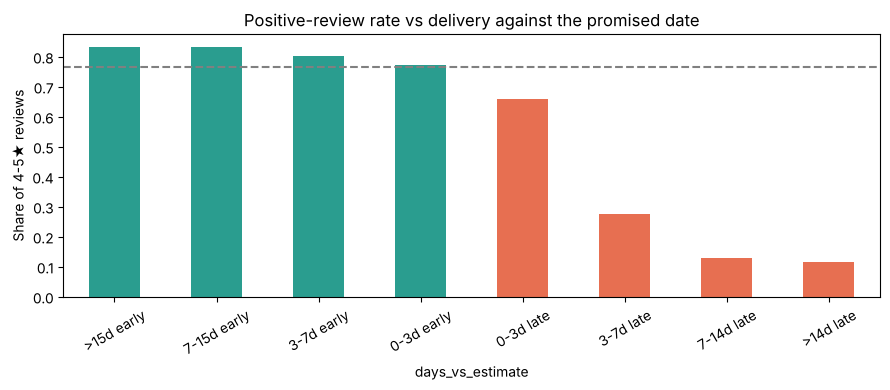

In [13]:
t = rate_by('days_vs_estimate', bins=[-100, -15, -7, -3, 0, 3, 7, 14, 200],
            labels=['>15d early', '7-15d early', '3-7d early', '0-3d early',
                    '0-3d late', '3-7d late', '7-14d late', '>14d late'])
ax = t['positive_rate'].plot(kind='bar', color=['#2a9d8f']*4 + ['#e76f51']*4, figsize=(9, 4))
ax.axhline(BASE, ls='--', c='grey'); ax.set_ylabel('Share of 4-5★ reviews')
ax.set_title('Positive-review rate vs delivery against the promised date'); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

### 4b. Order basket

In [14]:
display(rate_by('n_items', bins=[0, 1, 2, 3, 100], labels=['1', '2', '3', '4+']))
display(rate_by('n_sellers', bins=[0, 1, 2, 100], labels=['1', '2', '3+']))
display(rate_by('order_price', bins=[0, 30, 60, 100, 200, 500, 1e6]))
display(rate_by('freight_ratio', bins=[0, 0.1, 0.2, 0.4, 0.7, 1, 100]))

,positive_rate,n_orders,lift_vs_base
n_items,,,
1,0.788,79983,0.021
2,0.639,6783,-0.128
3,0.599,1208,-0.167
4+,0.554,879,-0.213


,positive_rate,n_orders,lift_vs_base
n_sellers,,,
1,0.777,87698,0.010
2,0.398,1102,-0.368


,positive_rate,n_orders,lift_vs_base
order_price,,,
"(0.0, 30.0]",0.791,13464,0.024
"(30.0, 60.0]",0.785,20078,0.018
"(60.0, 100.0]",0.774,18649,0.008
"(100.0, 200.0]",0.768,23199,0.002
"(200.0, 500.0]",0.735,10206,-0.032
"(500.0, 1000000.0]",0.734,3257,-0.032


,positive_rate,n_orders,lift_vs_base
freight_ratio,,,
"(0.0, 0.1]",0.782,13827,0.015
"(0.1, 0.2]",0.778,25420,0.012
"(0.2, 0.4]",0.770,28853,0.003
"(0.4, 0.7]",0.762,13487,-0.005
"(0.7, 1.0]",0.760,4134,-0.006
"(1.0, 100.0]",0.733,2826,-0.034


### 4c. Payment

In [15]:
display(rate_by('main_payment_type'))
display(rate_by('max_installments', bins=[0, 1, 3, 6, 10, 30], labels=['1', '2-3', '4-6', '7-10', '>10']))
display(rate_by('n_payment_methods', bins=[0, 1, 2, 100], labels=['1', '2', '3+']))

,positive_rate,n_orders,lift_vs_base
main_payment_type,,,
boleto,0.767,17819,0.000
credit_card,0.768,67544,0.001
debit_card,0.789,1373,0.022
voucher,0.734,2812,-0.032


,positive_rate,n_orders,lift_vs_base
max_installments,,,
1,0.777,43493,0.011
2-3,0.768,20523,0.001
4-6,0.756,14541,-0.010
7-10,0.738,10683,-0.029
>10,0.712,309,-0.055


,positive_rate,n_orders,lift_vs_base
n_payment_methods,,,
1,0.767,86820,0.001
2,0.750,2210,-0.017
3+,0.747,521,-0.020


### 4d. Product

In [16]:
cat = rate_by('main_category', min_n=500).sort_values('positive_rate')
display(pd.concat([cat.head(6), cat.tail(6)]))
display(rate_by('avg_photos', bins=[0, 1, 2, 4, 30], labels=['1', '2', '3-4', '5+']))
display(rate_by('total_weight_g', bins=[-1, 500, 2000, 10000, 1e6], labels=['<0.5kg', '0.5-2kg', '2-10kg', '>10kg']))

,positive_rate,n_orders,lift_vs_base
main_category,,,
office_furniture,0.631,1138,-0.136
bed_bath_table,0.725,8377,-0.041
telephony,0.746,3766,-0.020
furniture_decor,0.747,5735,-0.020
consoles_games,0.747,949,-0.020
baby,0.749,2550,-0.018
musical_instruments,0.799,553,0.033
perfumery,0.800,2831,0.034
small_appliances,0.801,572,0.034


,positive_rate,n_orders,lift_vs_base
avg_photos,,,
1,0.767,42923,-0.000
2,0.775,17519,0.009
3-4,0.773,17037,0.007
5+,0.786,10129,0.019


,positive_rate,n_orders,lift_vs_base
total_weight_g,,,
<0.5kg,0.783,35722,0.017
0.5-2kg,0.779,30745,0.012
2-10kg,0.757,17512,-0.010
>10kg,0.695,4874,-0.072


### 4e. Seller, customer and geography

In [17]:
display(rate_by('seller_prior_pos_rate', bins=[-0.01, 0.6, 0.7, 0.8, 0.9, 1.0]))
display(rate_by('is_repeat_customer'))
display(rate_by('cust_prior_pos_rate', bins=[-0.01, 0.5, 0.99, 1.0], labels=['<=50% positive', '51-99%', '100% positive']))
display(rate_by('same_state'))
display(rate_by('cust_seller_km', bins=[0, 50, 300, 800, 1500, 5000]))
display(rate_by('customer_state', min_n=1000).sort_values('positive_rate'))

,positive_rate,n_orders,lift_vs_base
seller_prior_pos_rate,,,
"(-0.01, 0.6]",0.657,6595,-0.110
"(0.6, 0.7]",0.718,9986,-0.048
"(0.7, 0.8]",0.765,33280,-0.001
"(0.8, 0.9]",0.811,24930,0.045
"(0.9, 1.0]",0.819,11050,0.053


,positive_rate,n_orders,lift_vs_base
is_repeat_customer,,,
0,0.767,86748,-0.000
1,0.772,2804,0.005


,positive_rate,n_orders,lift_vs_base
cust_prior_pos_rate,,,
<=50% positive,0.436,659,-0.331
100% positive,0.875,2120,0.108


,positive_rate,n_orders,lift_vs_base
same_state,,,
0,0.748,57653,-0.019
1,0.801,31899,0.034


,positive_rate,n_orders,lift_vs_base
cust_seller_km,,,
"(0, 50]",0.803,10792,0.037
"(50, 300]",0.799,17917,0.032
"(300, 800]",0.763,37623,-0.003
"(800, 1500]",0.761,13934,-0.005
"(1500, 5000]",0.727,8129,-0.040


,positive_rate,n_orders,lift_vs_base
customer_state,,,
CE,0.696,1196,-0.071
BA,0.704,3056,-0.063
RJ,0.705,11639,-0.062
PE,0.747,1488,-0.019
ES,0.750,1827,-0.017
GO,0.755,1806,-0.012
SC,0.764,3267,-0.003
DF,0.767,1926,0.001
MG,0.780,10481,0.013


### 4f. Timing

In [18]:
display(rate_by('purchase_dow'))
display(rate_by('black_friday_xmas'))
display(rate_by('seller_dispatch_days', bins=[-100, 1, 3, 7, 14, 400], labels=['<1d', '1-3d', '3-7d', '7-14d', '>14d']))

,positive_rate,n_orders,lift_vs_base
purchase_dow,,,
0,0.769,14629,0.002
1,0.771,14345,0.005
2,0.775,14017,0.009
3,0.766,13266,-0.001
4,0.752,12710,-0.015
5,0.759,9798,-0.008
6,0.771,10787,0.005


,positive_rate,n_orders,lift_vs_base
black_friday_xmas,,,
0,0.772,77662,0.006
1,0.730,11890,-0.037


,positive_rate,n_orders,lift_vs_base
seller_dispatch_days,,,
<1d,0.816,26556,0.049
1-3d,0.795,33753,0.028
3-7d,0.753,21648,-0.014
7-14d,0.664,4520,-0.103
>14d,0.469,1477,-0.298


## 5. Leakage check: features that must **not** be used
The model scores a customer **before** they review, so that Olist can target them. Any field created by, or after, the review cannot be used:

| Field | Why it leaks |
|---|---|
| `review_score` | It **is** the target |
| `review_comment_message` (text, length, sentiment) | Written at the same time as the score |
| `review_answer_timestamp` / response time | Only exists once the customer has answered |
| Seller/customer average score that **includes the current order** | Contains the target. Use the *prior-only* versions above |

Timing caveat: Olist sends the survey around delivery (`review_creation_date`). Delivery features are therefore legitimately known when the targeting decision is made. If you want to target *at purchase*, only basket, payment, product, seller-history and customer features are available. Delivery lateness would have to be **forecast**, e.g. from `promised_days`, distance and seller dispatch history.

In [19]:
df['comment_length'] = df['review_comment_message'].fillna('').str.len()
display(rate_by('comment_length', bins=[-1, 0, 50, 150, 1000], labels=['no comment', '1-50', '51-150', '>150']))
print('^ Strongly predictive, but only because it is part of the review itself. Exclude it.')

,positive_rate,n_orders,lift_vs_base
comment_length,,,
no comment,0.858,52149,0.091
1-50,0.785,17642,0.018
51-150,0.578,15197,-0.188
>150,0.283,4564,-0.483


^ Strongly predictive, but only because it is part of the review itself. Exclude it.


## 6. *(Beyond the brief)* Do the features hold up in a model?
The seminar only asks us to *identify* features. A quick gradient-boosted model is still a useful sanity check. It is trained on earlier orders and tested on later ones (a time-based split, because the history features are time-ordered), and it ranks which features carry the most signal.

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

features = ['is_delivered', 'delivery_days', 'promised_days', 'days_vs_estimate', 'is_late',
            'approval_hours', 'seller_dispatch_days', 'carrier_days', 'delivered_before_survey',
            'n_items', 'n_sellers', 'n_distinct_products', 'order_price', 'order_freight', 'freight_ratio',
            'total_weight_g', 'total_volume_cm3', 'avg_photos', 'avg_desc_length', 'avg_name_length',
            'payment_value', 'n_payment_methods', 'max_installments', 'used_voucher',
            'cust_seller_km', 'same_state', 'is_repeat_customer', 'cust_prior_pos_rate',
            'seller_prior_orders', 'seller_prior_pos_rate', 'seller_prior_late_rate',
            'purchase_month', 'purchase_dow', 'purchase_hour', 'has_items']
cat_feats = ['main_payment_type', 'main_category', 'customer_state', 'seller_state']

X = df[features].copy()
for c in cat_feats:
    X[c] = df[c].astype('category').cat.codes   # simple label encoding; -1 = missing
y = df['positive_review']

cut = int(len(df) * 0.8)        # df is sorted by purchase date -> train on past, test on future
X_tr, X_te, y_tr, y_te = X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]

cat_mask = [c in cat_feats for c in X.columns]
model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, categorical_features=cat_mask, random_state=42)
model.fit(X_tr, y_tr)

auc = roc_auc_score(y_te, model.predict_proba(X_te)[:, 1])
print(f'Test ROC-AUC (all features): {auc:.3f}')

# delivery-free model: what could we predict at the moment of purchase?
deliv = ['is_delivered', 'delivery_days', 'days_vs_estimate', 'is_late', 'seller_dispatch_days',
         'carrier_days', 'delivered_before_survey']
keep = [c for c in X.columns if c not in deliv]
m2 = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                    categorical_features=[c in cat_feats for c in keep], random_state=42)
m2.fit(X_tr[keep], y_tr)
print(f'Test ROC-AUC (purchase-time features only): {roc_auc_score(y_te, m2.predict_proba(X_te[keep])[:, 1]):.3f}')

Test ROC-AUC (all features): 0.706


Test ROC-AUC (purchase-time features only): 0.620


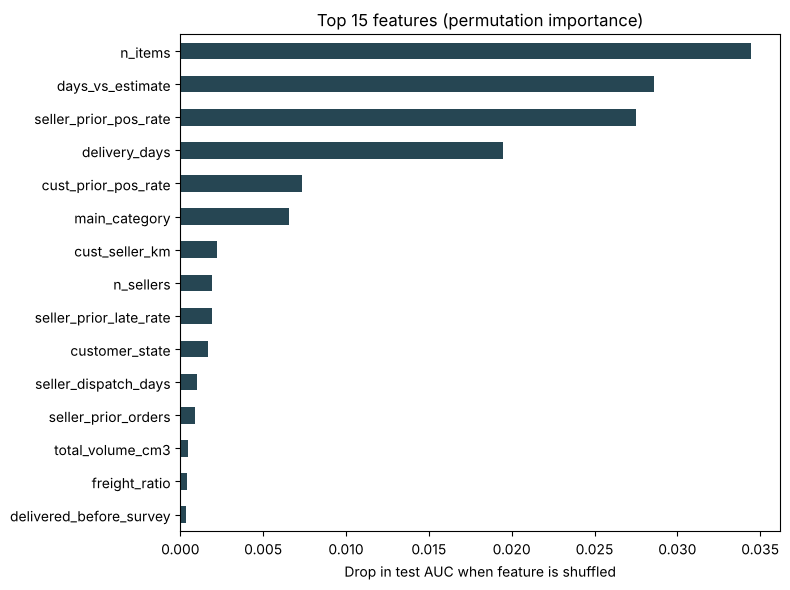

n_items                   0.034
days_vs_estimate          0.029
seller_prior_pos_rate     0.027
delivery_days             0.019
cust_prior_pos_rate       0.007
main_category             0.007
cust_seller_km            0.002
n_sellers                 0.002
seller_prior_late_rate    0.002
customer_state            0.002
seller_dispatch_days      0.001
seller_prior_orders       0.001
total_volume_cm3          0.000
freight_ratio             0.000
delivered_before_survey   0.000
dtype: float64

In [21]:
pi = permutation_importance(model, X_te, y_te, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False).head(15)
ax = imp[::-1].plot(kind='barh', figsize=(8, 6), color='#264653')
ax.set_xlabel('Drop in test AUC when feature is shuffled'); ax.set_title('Top 15 features (permutation importance)')
plt.tight_layout(); plt.show()
imp

## 7. Conclusions: recommended feature set
Baseline: **76.7%** of reviews are 4–5★.

| Rank | Feature (theme) | Evidence from the data | Type |
|---|---|---|---|
| 1 | `days_vs_estimate`, `is_late` (delivery) | Early: 80–83% positive → 3–7 days late: 28% → >14 days late: 12% | Data-driven calc |
| 2 | `order_status` / `is_delivered` (delivery) | Delivered 79% vs shipped / cancelled / unavailable 4–20% | Boolean encode |
| 3 | `delivery_days` (delivery) | ≤5 days: 87% vs 30–60 days: 26% | Data-driven calc |
| 4 | `delivered_before_survey` (delivery) | Survey sent before the parcel arrived: 34% vs 82% | Theory-driven |
| 5 | `seller_dispatch_days` (seller ops) | Dispatched in <1 day: 82% vs >14 days: 47% | Data-driven calc |
| 6 | `n_items` (basket) | 1 item: 79% vs 4+ items: 55% (top permutation importance) | Aggregation |
| 7 | `n_sellers` / `multi_seller` (basket) | 1 seller: 78% vs 2 sellers: 40% (split shipments) | Aggregation |
| 8 | `seller_prior_pos_rate` (seller reputation, prior orders only) | Seller history ≤60% positive → 66%; >90% → 82% | Theory + leakage-safe |
| 9 | `cust_prior_pos_rate` (customer history) | Previously always positive: 88% vs previously negative: 44% (repeat buyers only) | Theory + leakage-safe |
| 10 | `main_category` (product) | Office furniture 63%, bed/bath 73% vs luggage 84%, stationery 82% | Categorical encode |
| 11 | `cust_seller_km`, `same_state`, `customer_state` (geography) | Same state 80% vs 75%; RJ/BA/CE about 70% vs SP/PR about 79% | Join (geolocation) |
| 12 | `total_weight_g`, `black_friday_xmas`, `max_installments`, `order_price` | Small effects: >10kg 70%, Nov–Dec 73%, >10 instalments 71% | Secondary |

**Weak or no signal:** payment type, number of payment methods, day of week, number of product photos, freight ratio.

**Exclude (leakage):** `review_comment_message` and anything derived from it (comment length looks hugely predictive: >150 characters gives only 28% positive), review answer time, and any average score that includes the current order.

**Model check (beyond the brief):** a gradient-boosted model trained on past orders and tested on later ones reaches **ROC-AUC ≈ 0.71** with all features. Using only features known at purchase (no delivery outcome), it reaches **≈ 0.62**. The delivery experience therefore drives most of the predictable signal, so the most sensible point to target a customer is **after delivery**, not at checkout.

**Business implication:** Olist should prioritise review incentives for customers whose order arrived **on time or early, in one shipment, from a single, well-rated seller**, and repeat customers who have reviewed positively before. Incentivising customers with late or split deliveries would mostly generate 1–2★ reviews.

**Ethical / practical note:** soliciting reviews only from customers predicted to be happy biases the public rating. Many platforms and consumer-protection regimes restrict selective or incentivised review solicitation, so this needs to be checked before deployment.